#**Clase práctica 3: Medidas descriptivas y estadística bivariada**
## Estadística Descriptiva · Usando R



En las clases anteriores clasificamos variables y construimos tablas de frecuencia y gráficos. Hoy damos el paso siguiente: **resumir una variable con números** y **estudiar dos variables al mismo tiempo**, usando el Índice Departamental de Competitividad (IDC) 2025-2026.

**El caso:** *¿Qué tan competitivos son los departamentos de Colombia, qué tan desiguales son entre sí, y qué se asocia con esa competitividad?*

Lo que vamos a hacer:

1. **Medidas de tendencia central:** media, mediana y moda.
2. **Medidas de dispersión:** varianza, desviación estándar y coeficiente de variación.
3. **Cuartiles y gráfica de caja y bigotes** (boxplot), incluida la detección de datos atípicos.
4. **Estadística bivariada:** tablas cruzadas, covarianza, correlación y diagrama de dispersión.
5. Una **interpretación general** del caso.

Cada celda de código usa funciones de **R base** (sin paquetes adicionales) y va acompañada de una explicación de qué hace cada función y de una **breve interpretación** del resultado.

## 0. Preparar el entorno



In [1]:
idc <- read.csv("idc_2025_2026.csv", encoding = "UTF-8")

# Nota: como hemos visto anteriormente, en este primer paso debo tener presente el formato de mi base de datos: excel o csv
# (hasta donde hemos trabajado en el curso)

In [2]:
head(idc[, c("departamento", "region", "idc_2025", "idc_2026")])

# Nota: permite visualizar la base de datos, en el caso de los nombres dentro de los parentesis, corresponde al de las columnas
#       en su caso, posiblemente el nombre de las columnas (las cuales corresponde a las variables), sean diferentes. También
#       en clases anteriores, vimos que es posible simplemente colocar el nombre de la base de datos y aparece la información.

,departamento,region,idc_2025,idc_2026
,<chr>,<chr>,<dbl>,<dbl>
1,"Bogotá, D.C.",Central,8.0392,7.9560
2,Antioquia,Eje cafetero y Antioquia,6.8033,6.9049
3,Valle del Cauca,Pacífico,6.2906,6.4269
4,Risaralda,Eje cafetero y Antioquia,6.2024,6.3548
5,Santander,Santanderes,6.2794,6.3197
6,Atlántico,Caribe,6.0945,6.2231


## 1. Medidas de tendencia central

Una medida de tendencia central responde: **¿cuál es el valor "típico" de la variable?** Trabajaremos con `idc_2026`, el puntaje general del IDC en 2026 (variable cuantitativa continua, una observación por departamento; Bogotá D.C. cuenta como una unidad).

### 1.1 Media y mediana

- **Media** $\bar{X} = \dfrac{\sum X_i}{n}$: el promedio. En R: `mean()`.
- **Mediana:** el valor que deja la mitad de los datos por debajo y la otra mitad por encima. En R: `median()`.

Para no escribir `idc$idc_2026` cada vez, guardamos esa columna en un objeto nuevo con la flecha de asignación `<-`. El símbolo `$` extrae una columna del `data.frame`:

In [4]:
idc26 <- idc$idc_2026
mean(idc26)
median(idc26)

# Nota: en esta opción, se asigna toda la columna al objeto que hemos denominado "idc26", recuerde que también tiene la opción
#       como en la clase anterior, de seleccionar la variable usando el $. Ambas opciones da el mismo resultados.

[1] 5.067994

[1] 5.0763

> **Interpretación:** la media (5.07) y la mediana (5.08) son casi idénticas. Cuando ambas coinciden, la distribución es aproximadamente **simétrica**: no hay valores extremos que "jalen" la media hacia un lado. El departamento típico (representativo) tiene un IDC de alrededor de 5 puntos sobre 10.

### 1.2 ¿Dónde está Norte de Santander?

Para ubicar un departamento usamos una **condición lógica**: `idc$departamento == "Norte de Santander"` devuelve `TRUE` en la fila que cumple y `FALSE` en las demás, y con ella filtramos la tabla. Después comparamos su puntaje con el de todos: `idc26 > ns_idc` da `TRUE` para cada departamento con mayor puntaje, y `sum()` cuenta cuántos `TRUE` hay (R trata `TRUE` como 1 y `FALSE` como 0):

In [7]:
idc[idc$departamento == "Norte de Santander", c("departamento", "region", "idc_2026", "rank_2026")]

# Nota: en este caso, la idea central es poder identificar un departamento particular. Esto debe hacerse, según la necesidad
#       o según lo requerido. Para hacer este procedimiento, se debe hacer primero la identificación de una variable de texto
#       que contiene el nombre de las unidades de análisis, por ejemplo, en este caso, la columna departamentos. Lo que se
#       encuentra luego en c(), corresponde al nombre de las columnas que desea visualizar.



,departamento,region,idc_2026,rank_2026
,<chr>,<chr>,<dbl>,<int>
13,Norte de Santander,Santanderes,5.3881,13


> **Interpretación:** Norte de Santander tiene un IDC de 5.39, cerca de **0.32 puntos por encima** de la media (5.07). Hay 12 departamentos por delante, lo que lo ubica en el puesto 13 de 33: en la mitad superior, pero sin destacarse.

### 1.3 Moda

La **moda** es el valor (o categoría) que más se repite. **R base no trae una función para calcularla**, así que la obtenemos con herramientas que ya conocemos:

- `table()` cuenta las repeticiones de cada valor.
- `which.max()` devuelve la **posición** del valor más grande de un vector.
- `names()` nos da el nombre de esa posición, es decir, la categoría.

Para una variable **cualitativa** como `region`, la moda es la categoría con más departamentos:

In [8]:
tabla_region <- table(idc$region)
tabla_region
names(which.max(tabla_region))


                Amazonía                   Caribe                  Central 
                       6                        7                        5 
Eje cafetero y Antioquia         Llanos-Orinoquía                 Pacífico 
                       4                        4                        4 
             Santanderes         Seaflower Region 
                       2                        1 

[1] "Caribe"

## 2. Medidas de dispersión

La tendencia central no basta: dos conjuntos de datos pueden tener el mismo promedio y ser muy distintos en qué tan "regados" están. La dispersión mide **cuánto se alejan los datos de la media**.

### 2.1 Rango, varianza y desviación estándar

- **Rango:** `max() - min()`, la distancia entre el valor más alto y el más bajo.
- **Varianza** $S^2$: promedio de las desviaciones al cuadrado respecto a la media. En R: `var()`.
- **Desviación estándar** $S = \sqrt{S^2}$: la raíz de la varianza, que queda en las **mismas unidades** que los datos. En R: `sd()`.

In [10]:
max(idc26) - min(idc26)
var(idc26)
sd(idc26)

[1] 5.1475

[1] 1.380266

[1] 1.174847

> **Interpretación:** el IDC va de 2.81 a 7.96, un **rango de 5.15 puntos**. La desviación estándar es de aproximadamente **1.38 puntos** (1.17 con la fórmula de R): un departamento típico se aleja de la media unos 1.2 puntos.

### 2.2 Coeficiente de variación

El **coeficiente de variación** $CV = \dfrac{S}{\bar{X}} \cdot 100\%$ expresa la desviación estándar como porcentaje de la media. Como no tiene unidades, permite **comparar la dispersión de variables distintas**:

In [12]:
sd(idc26) / mean(idc26) * 100

[1] 23.1817

> **Interpretación:** el CV del IDC es de **23.2%**: la desviación estándar equivale a algo menos de una cuarta parte de la media. Por sí solo es difícil decir si es "mucho" o "poco"; el CV cobra sentido al **comparar** variables, como hacemos a continuación.

### 2.3 Comparar la dispersión entre variables

Vamos a comparar el IDC con dos de sus pilares: **TIC** y **innovación**. Para no repetir la fórmula, creamos nuestra propia **función** con `function()`: recibe un vector `v` y devuelve su CV. Luego armamos una tabla con `data.frame()` y redondeamos con `round()`:

In [14]:
cv <- function(v) sd(v) / mean(v) * 100

comparacion <- data.frame(
  variable = c("idc_2026", "tic_2026", "innovacion_2026"),
  media = c(mean(idc$idc_2026), mean(idc$tic_2026), mean(idc$innovacion_2026)),
  desv_est = c(sd(idc$idc_2026), sd(idc$tic_2026), sd(idc$innovacion_2026)),
  cv = c(cv(idc$idc_2026), cv(idc$tic_2026), cv(idc$innovacion_2026))
)
comparacion$media <- round(comparacion$media, 2)
comparacion$desv_est <- round(comparacion$desv_est, 2)
comparacion$cv <- round(comparacion$cv, 1)
comparacion

# Nota: este bloque de código, permite crear una tabla de comparación para distintas variables que tenga en su base de datos
#.      para seguirlo, concentrate en identificar donde van o donde corresponde el uso de las variables, por ejemplo la
#       expresión "idc$tic_2026" es la variable tic_2026 de los datos de idc.

variable,media,desv_est,cv
<chr>,<dbl>,<dbl>,<dbl>
idc_2026,5.07,1.17,23.2
tic_2026,4.55,1.96,43.1
innovacion_2026,2.37,1.33,56.3


> **Interpretación:** aunque la desviación estándar de **TIC** (1.96) es mayor que la de **innovación** (1.33), el CV de innovación es el más alto (**56.3%**). La razón es que su media es muy baja (2.37): casi todos los departamentos puntúan mal en innovación, pero unos pocos puntúan mucho mejor, así que las diferencias son enormes *en relación con el nivel promedio*. Comparar solo desviaciones estándar habría escondido esto; el CV lo revela.

## 3. Cuartiles y gráfica de caja y bigotes

Los **cuartiles** dividen los datos ordenados en cuatro partes iguales: $Q_1$ deja el 25% de los datos por debajo, $Q_2$ es la mediana (50%) y $Q_3$ deja el 75% por debajo. El **rango intercuartílico** $IQR = Q_3 - Q_1$ mide el ancho del 50% central de los datos.

### 3.1 Resumen de cinco números

- `summary()` da mínimo, $Q_1$, mediana, media, $Q_3$ y máximo.
- `quantile()` calcula los cuantiles que se le pidan en `probs` (0.25 = 25%).
- `IQR()` calcula $Q_3 - Q_1$.

In [15]:
summary(idc26)
quantile(idc26, probs = c(0.25, 0.50, 0.75))
IQR(idc26)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  2.808   4.389   5.076   5.068   5.992   7.956 

25%    50%    75% 
4.3890 5.0763 5.9924

[1] 1.6034

> **Interpretación:** la mitad "central" de los departamentos tiene un IDC entre **4.39** ($Q_1$) y **5.99** ($Q_3$); el rango intercuartílico es de **1.60** puntos. El 75% más competitivo supera 5.99 puntos y el 25% menos competitivo no llega a 4.39.

### 3.2 Gráfica de caja y bigotes

`boxplot()` dibuja los cuartiles:

- La **caja** va de $Q_1$ a $Q_3$ (el 50% central de los datos).
- La **línea gruesa** dentro de la caja es la **mediana**.
- Los **bigotes** llegan hasta el dato más lejano que no se aleje más de $1.5 \times IQR$ de la caja.
- Los **puntos sueltos** más allá de los bigotes son **datos atípicos** (*outliers*).

`horizontal = TRUE` la dibuja acostada; `col`, `main` y `xlab` fijan color, título y etiqueta del eje:

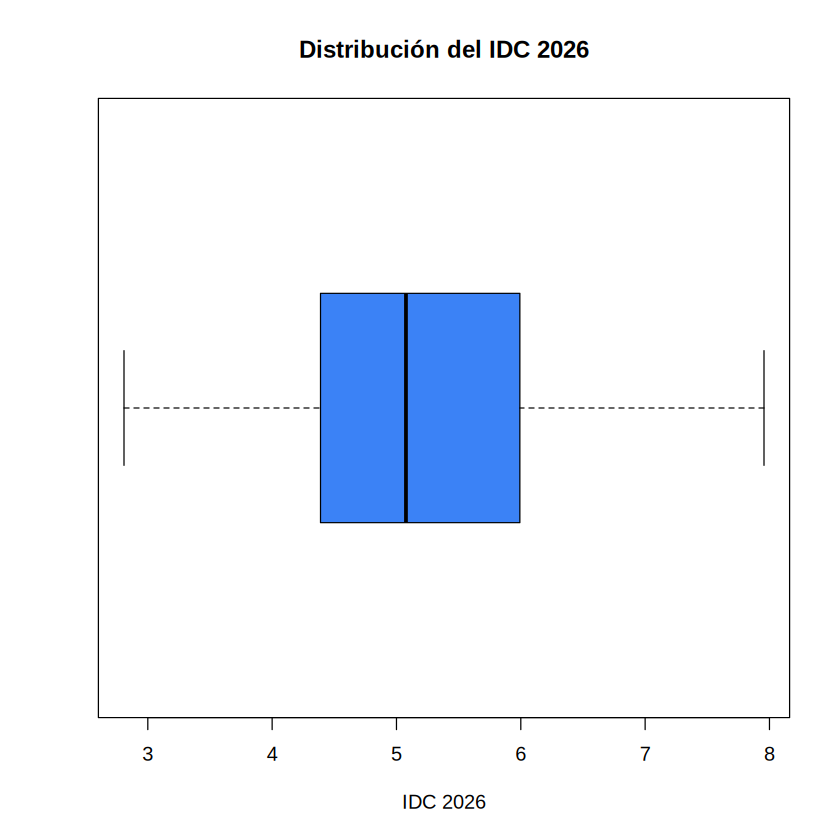

In [16]:
boxplot(idc26,
        horizontal = TRUE,
        col = "#3B82F6",
        main = "Distribución del IDC 2026",
        xlab = "IDC 2026")

> **Interpretación:** la mediana queda casi en el centro de la caja y los bigotes tienen largos similares: la distribución es **simétrica**, como ya intuíamos al ver que media y mediana coinciden. No aparecen puntos sueltos, es decir, **ningún departamento es atípico** en el IDC general.

### 3.3 Datos atípicos

`boxplot.stats(x)$out` devuelve exactamente los valores que el boxplot marcaría como atípicos (si no hay ninguno, devuelve `numeric(0)`, un vector numérico vacío). Probémoslo con el IDC y con el pilar de **infraestructura**. Para saber *qué departamentos* son, usamos el operador `%in%`, que pregunta si cada valor de una columna está dentro de un conjunto de valores:

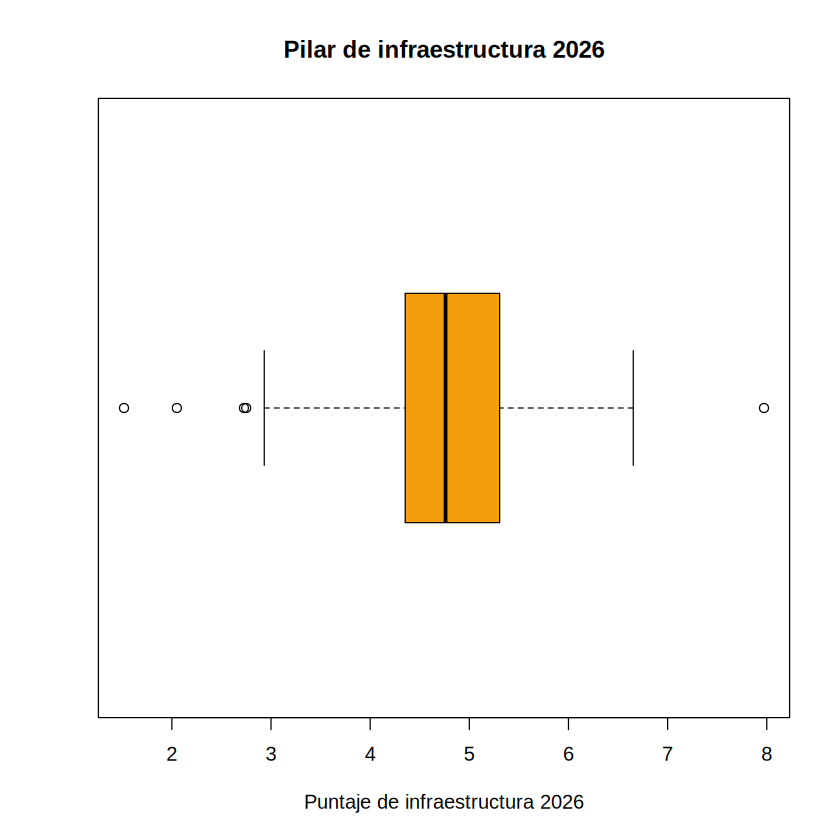

In [18]:
boxplot(idc$infraestructura_2026,
        horizontal = TRUE,
        col = "#F59E0B",
        main = "Pilar de infraestructura 2026",
        xlab = "Puntaje de infraestructura 2026")

In [17]:
boxplot.stats(idc26)$out

# Nota: permite identificar datos atípicos, en el caso de la siguiente línea de código, se incluye una columna particular.

atipicos_infra <- boxplot.stats(idc$infraestructura_2026)$out
atipicos_infra
idc$departamento[idc$infraestructura_2026 %in% atipicos_infra]

numeric(0)

[1] 7.9720 2.7270 2.0502 1.5174 2.7497

[1] "Bogotá, D.C." "Chocó"        "Guainía"      "Vichada"      "Vaupés"

> **Interpretación:** el IDC general no tiene atípicos, pero el pilar de **infraestructura** sí: **5 departamentos**. **Bogotá D.C.** (7.97) es atípica por arriba, y **Chocó, Guainía, Vichada y Vaupés** (entre 1.5 y 2.75) lo son por abajo. Un indicador general puede verse "parejo" mientras uno de sus componentes esconde brechas enormes, aquí en infraestructura.

### 3.4 Caja y bigotes por grupos

La fórmula `idc_2026 ~ region` se lee "el IDC según la región": `boxplot()` dibuja una caja por cada región, lo que permite comparar grupos en una sola gráfica. `las = 2` rota las etiquetas del eje, y `par(mar = ...)` ajusta los márgenes de la figura (abajo, izquierda, arriba, derecha) para que quepan los nombres largos. Con `tapply()` calculamos la mediana de cada región para tener los números a la vista:

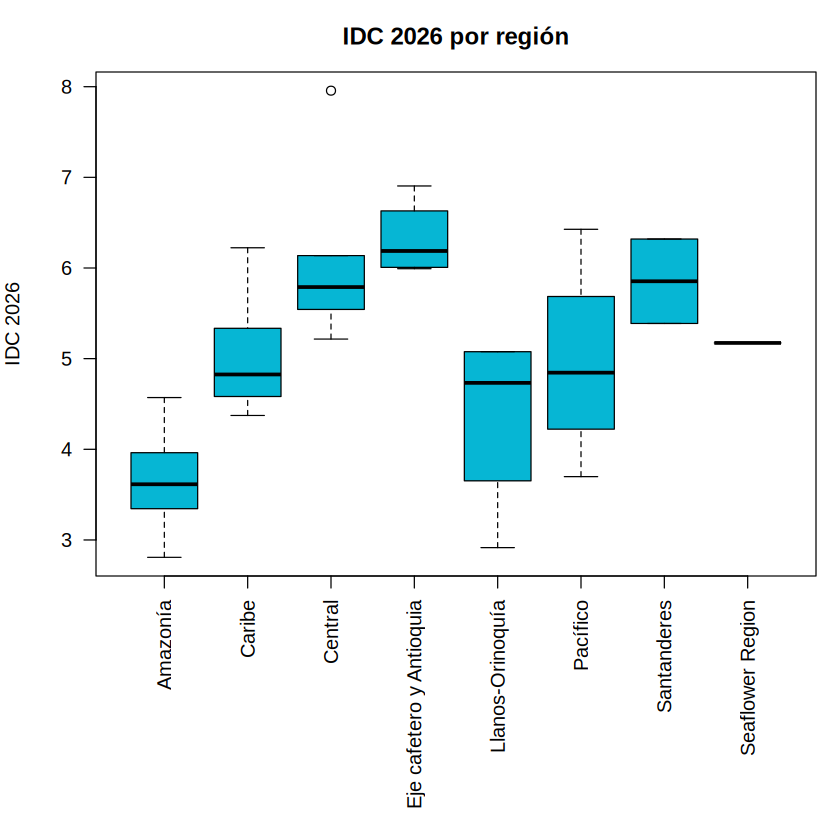

In [19]:
par(mar = c(11, 4, 3, 1))
boxplot(idc_2026 ~ region,
        data = idc,
        las = 2,
        col = "#06B6D4",
        main = "IDC 2026 por región",
        xlab = "",
        ylab = "IDC 2026")
par(mar = c(5, 4, 4, 2))

In [20]:
round(tapply(idc26, idc$region, median), 2)

Amazonía                   Caribe                  Central 
                    3.61                     4.83                     5.79 
Eje cafetero y Antioquia         Llanos-Orinoquía                 Pacífico 
                    6.19                     4.73                     4.85 
             Santanderes         Seaflower Region 
                    5.85                     5.17

> **Interpretación:** la región con mayor mediana es **Eje cafetero y Antioquia** (6.19), seguida de **Santanderes** (5.85) y **Central** (5.79); la de menor mediana es **Amazonía** (3.61), claramente por debajo de las demás. **Bogotá D.C.** aparece como dato atípico dentro de la región Central. **Seaflower** tiene un solo departamento, por eso su "caja" se reduce a una línea. Las cajas anchas de **Llanos-Orinoquía** y **Pacífico** indican que hay mucha diferencia *dentro* de esas regiones.

## 4. Estadística bivariada

Hasta aquí analizamos una variable a la vez. La estadística **bivariada** estudia **dos variables juntas** para ver si están relacionadas.

### 4.1 Covarianza y correlación (cuantitativa × cuantitativa)

- **Covarianza** $S_{XY} = \dfrac{\sum (X_i - \bar{X})(Y_i - \bar{Y})}{n-1}$: indica si las dos variables **se mueven en el mismo sentido** (positiva), en sentido **contrario** (negativa), o sin relación (cercana a cero). Su magnitud depende de las unidades, por eso es difícil de interpretar sola. En R: `cov(x, y)`.
- **Correlación de Pearson** $r = \dfrac{S_{XY}}{S_X S_Y}$: es la covarianza "estandarizada", siempre entre $-1$ y $1$, sin unidades. En R: `cor(x, y)`.

Relacionemos el IDC con el pilar **TIC** (tecnologías de la información y comunicación):

In [25]:
cov(idc$idc_2026, idc$tic_2026)
cor(idc$idc_2026, idc$tic_2026)

[1] 2.207334

[1] 0.9578764

Y la contrastamos con un pilar que **no** parece relacionado, **sostenibilidad**:

In [26]:
cov(idc$idc_2026, idc$sostenibilidad_2026)
cor(idc$idc_2026, idc$sostenibilidad_2026)

[1] -0.08452977

[1] -0.07833614

Por último, `cor()` aplicada a varias columnas a la vez devuelve la **matriz de correlaciones** entre todas ellas (`idc[, variables]` selecciona las columnas con los nombres guardados en `variables`):

In [27]:
variables <- c("idc_2026", "tic_2026", "edu_superior_2026", "innovacion_2026", "sostenibilidad_2026")

# Nota: lo primero es identificar el nombre de las variables para generar una matriz de correlación

round(cor(idc[, variables]), 2)

,idc_2026,tic_2026,edu_superior_2026,innovacion_2026,sostenibilidad_2026
idc_2026,1.00,0.96,0.95,0.86,-0.08
tic_2026,0.96,1.00,0.91,0.87,-0.11
edu_superior_2026,0.95,0.91,1.00,0.86,-0.18
innovacion_2026,0.86,0.87,0.86,1.00,-0.07
sostenibilidad_2026,-0.08,-0.11,-0.18,-0.07,1.00


> **Interpretación:** la covarianza entre IDC y TIC es positiva (2.21): cuando un departamento puntúa alto en TIC, tiende a puntuar alto en el IDC. Pero el 2.21 no dice *qué tan fuerte* es la relación; para eso está la correlación: **r = 0.96**, una relación lineal positiva **muy fuerte**. Con sostenibilidad, en cambio, la correlación es **−0.08**, prácticamente **cero**: no hay relación lineal. En la matriz, educación superior (0.95) e innovación (0.86) también acompañan de cerca al IDC, mientras que sostenibilidad queda con correlaciones cercanas a cero o ligeramente negativas con todas.

### 4.2 Diagrama de dispersión

El **diagrama de dispersión** muestra cada departamento como un punto: eje horizontal = una variable, eje vertical = la otra. Es la mejor forma de *ver* lo que resume la correlación.

- `plot(x, y)` dibuja los puntos (`pch = 19` los hace sólidos).
- `abline(lm(y ~ x))` agrega la **recta de ajuste**, la línea que mejor resume la tendencia (`lm()` ajusta un modelo lineal; lo estudiaremos en detalle más adelante, aquí solo la usamos como guía visual).
- `points()` y `text()` resaltan y rotulan a Norte de Santander.
- `par(mfrow = c(1, 2))` pone dos gráficos lado a lado, y `par(mfrow = c(1, 1))` vuelve al formato normal.

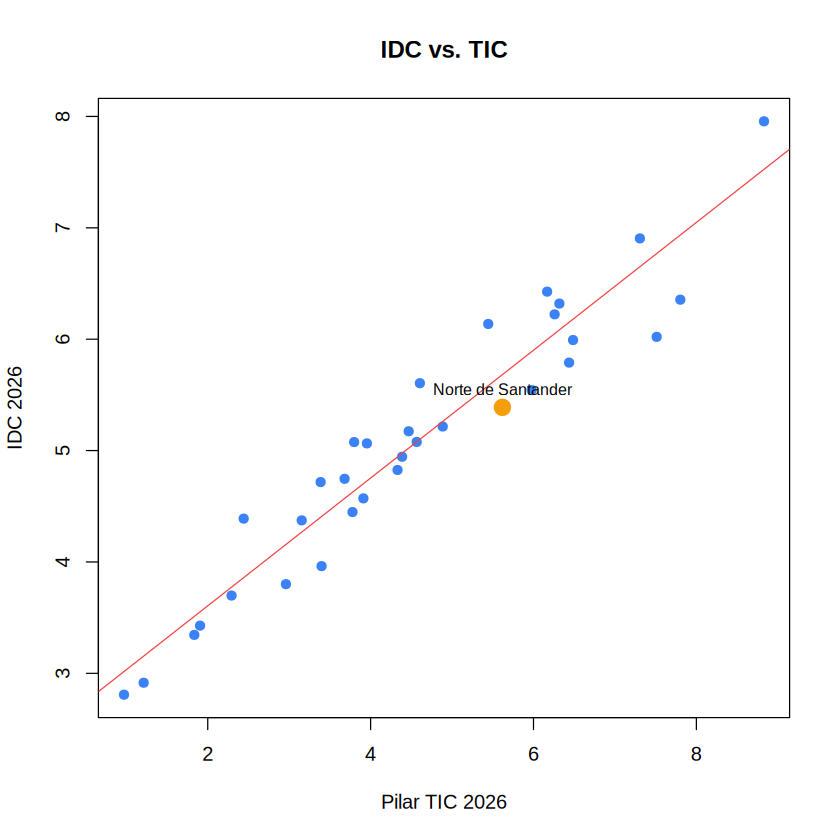

In [31]:
ns <- idc$departamento == "Norte de Santander"

plot(idc$tic_2026, idc$idc_2026,
     pch = 19, col = "#3B82F6",
     xlab = "Pilar TIC 2026", ylab = "IDC 2026",
     main = "IDC vs. TIC")
abline(lm(idc_2026 ~ tic_2026, data = idc), col = "#EF4444", lwd = 1)
points(idc$tic_2026[ns], idc$idc_2026[ns], pch = 19, col = "#F59E0B", cex = 1.8)
text(idc$tic_2026[ns], idc$idc_2026[ns], labels = "Norte de Santander", pos = 3, cex = 0.8)



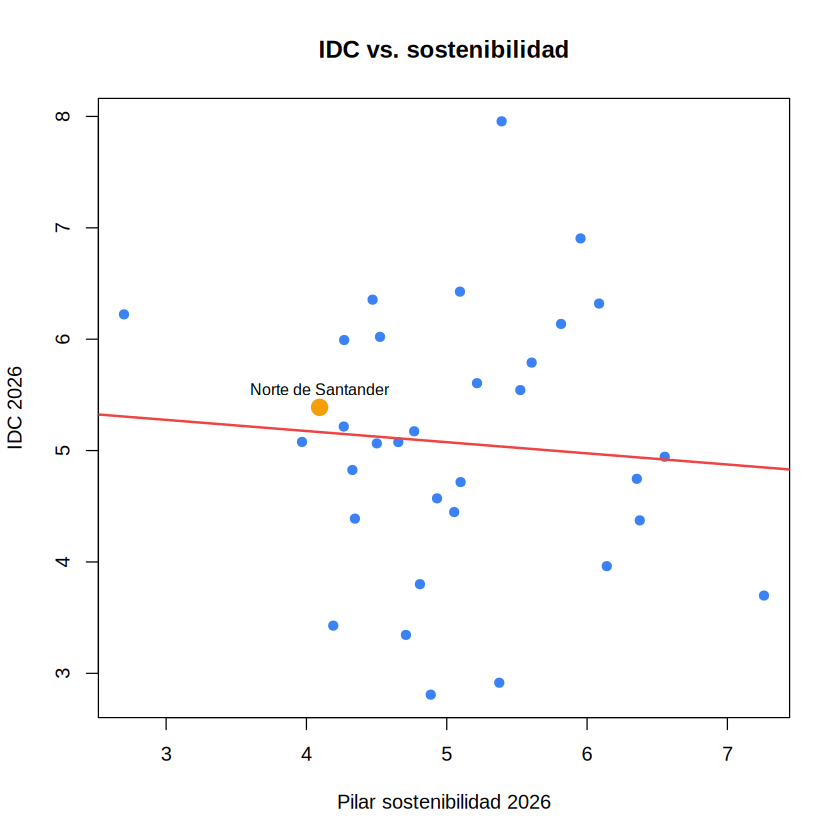

In [29]:
plot(idc$sostenibilidad_2026, idc$idc_2026,
     pch = 19, col = "#3B82F6",
     xlab = "Pilar sostenibilidad 2026", ylab = "IDC 2026",
     main = "IDC vs. sostenibilidad")
abline(lm(idc_2026 ~ sostenibilidad_2026, data = idc), col = "#EF4444", lwd = 2)
points(idc$sostenibilidad_2026[ns], idc$idc_2026[ns], pch = 19, col = "#F59E0B", cex = 1.8)
text(idc$sostenibilidad_2026[ns], idc$idc_2026[ns], labels = "Norte de Santander", pos = 3, cex = 0.8)

> **Interpretación:** a la izquierda, los puntos se alinean a lo largo de una recta ascendente: **a más TIC, más IDC** (la correlación de 0.96 hecha imagen). Norte de Santander (naranja) tiene un TIC de 5.62, por encima del promedio (4.55), pero queda **ligeramente por debajo de la recta**: su IDC (5.39) es unos 0.3 puntos menor que el que "se esperaría" para su nivel de TIC. A la derecha, la nube de puntos **no muestra ningún patrón** (correlación ≈ 0); allí Norte de Santander tiene una sostenibilidad de 4.09, por debajo del promedio (5.07): solo 2 departamentos puntúan menos.
>
> **Dos precauciones:** (1) *correlación no es causalidad*: que dos variables vayan juntas no prueba que una cause la otra; (2) el TIC es uno de los pilares con los que se **construye** el IDC, así que parte de esa correlación tan alta es mecánica.

## 5. Interpretación general del caso

**¿Qué tan competitivos son los departamentos y qué tan desiguales son entre sí?** El departamento típico obtiene unos 5 puntos sobre 10 (media 5.07, mediana 5.08, clase modal entre 5 y 6), y la distribución es **simétrica y sin datos atípicos**. La dispersión es **moderada**: la desviación estándar es de unos 1.2 puntos (CV de 23%), pero entre los extremos hay más de 5 puntos de distancia (de 2.81 en Vaupés a 7.96 en Bogotá D.C.). Esa brecha tiene **cara territorial**: Eje cafetero y Antioquia, Santanderes y Central lideran, mientras que Amazonía queda claramente por debajo, y regiones como Llanos-Orinoquía y Pacífico son internamente muy heterogéneas.

**Un indicador "parejo" esconde brechas en sus componentes.** El IDC general no tiene atípicos, pero el pilar de infraestructura sí (Bogotá muy por encima; Chocó, Guainía, Vichada y Vaupés muy por debajo), y el pilar de innovación tiene el CV más alto (56%): casi todos puntúan bajo, pero con enormes diferencias relativas. Comparar solo promedios, o solo desviaciones estándar, habría ocultado estos matices.

**¿Quién mejoró y qué se asocia con la competitividad?** Entre 2025 y 2026, 16 departamentos mejoraron, 14 se mantuvieron estables y 3 retrocedieron. Las mejoras se concentraron en el Caribe, el Eje cafetero y Antioquia, y Llanos-Orinoquía, pero **no dependen del nivel de partida**: los departamentos de nivel bajo y alto mejoraron en la misma proporción. En cuanto a asociaciones, el IDC se mueve casi a la par de TIC (r = 0.96) y educación superior (r = 0.95), y no se relaciona linealmente con sostenibilidad (r = −0.08). Hay que recordar que parte de esas correlaciones altas es mecánica, pues los pilares forman el índice.

**Norte de Santander** ocupa el puesto 13 de 33: algo por encima de la media (5.39 frente a 5.07), con un buen desempeño relativo en TIC pero una sostenibilidad baja (solo 2 departamentos puntúan menos) y un IDC ligeramente inferior al que sugeriría su nivel de TIC. Mejoró en el último año (+0.07 puntos), dentro de la región Santanderes, donde convive con Santander, de mayor puntaje.

**Limitaciones:** son solo 33 observaciones y varias regiones tienen entre 1 y 4 departamentos, así que los porcentajes por región son frágiles; y la correlación describe asociación lineal, no causalidad.

## 6. Resumen (código)

- **Tendencia central:** `mean()`, `median()`; la moda no existe en R base, se obtiene con `table()` + `which.max()` (o con la clase modal usando `cut()`). Si media y mediana difieren mucho, hay asimetría o atípicos.
- **Dispersión:** `var()`, `sd()` (dividen entre $n-1$) y el coeficiente de variación $S/\bar{X}\cdot 100\%$, que permite comparar variables con distinta escala o nivel.
- **Cuartiles y boxplot:** `summary()`, `quantile()`, `IQR()` y `boxplot()`; `boxplot.stats(x)$out` identifica los atípicos, y `boxplot(y ~ grupo)` compara grupos.
- **Bivariada cualitativa:** `table(a, b)` para la tabla cruzada, `addmargins()` para los totales y `prop.table(margin = 1 o 2)` para los porcentajes por fila o columna.
- **Bivariada cuantitativa:** `cov()` indica el sentido de la relación (depende de las unidades); `cor()` indica sentido e intensidad entre $-1$ y $1$; el diagrama de dispersión (`plot()`) permite *ver* la relación y detectar datos extraños.
- **Correlación no es causalidad.**


